In [1]:
!pip install -q timm torchaudio seaborn scikit-learn librosa

import os, re, time, warnings
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler, ConcatDataset
import torchaudio, torchaudio.transforms as TAT, timm
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix, classification_report
warnings.filterwarnings('ignore')

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

SAVE_DIR = './'
os.makedirs(SAVE_DIR, exist_ok=True)
CLUSTER_CSV_PATH = '/kaggle/input/datasets/mohammadbahgat/hdbscan-clustered/hdbscan_cluster_results.csv'
NPY_DIR          = '/kaggle/input/datasets/alieldinalaa/nn-cmp27-dataset/'
USE_PRECOMPUTED_NPY = False

MODEL_A_SAVE  = os.path.join(SAVE_DIR, 'best_sslam_model_A.pt')
MODEL_B_SAVE  = os.path.join(SAVE_DIR, 'best_sslam_model_B.pt')

SAMPLE_RATE, DURATION_SEC = 16_000, 11.0
N_MELS, N_FFT, HOP_LENGTH = 128, 1024, 512
TARGET_FRAMES = 344

BATCH_SIZE, EPOCHS, LR = 80, 25, 5e-5
NUM_CLASSES = 6
NUM_WORKERS = 4
LABEL_SMOOTH_TRAIN = 0.1
MIXUP_ALPHA = 0.2
WEIGHT_DECAY = 5e-3
FREQ_MASK_PARAM = 12
TIME_MASK_PARAM = 30

CLASS_NAMES = ['M1 Normal','M1 Abnormal','M2 Normal','M2 Abnormal','M3 Normal','M3 Abnormal']
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


In [2]:
print(f'Loading cluster CSV: {CLUSTER_CSV_PATH}')
df_all = pd.read_csv(CLUSTER_CSV_PATH)
if 'true_label' in df_all.columns and 'label' not in df_all.columns:
    df_all = df_all.rename(columns={'true_label': 'label'})

df_clean = df_all[df_all['cluster'] != -1].reset_index(drop=True)

def get_label_from_path(path):
    path = str(path).replace('\\', '/')
    parts = path.split('/')
    machine = parts[1].replace('Machine ', 'M')
    cond = parts[3]
    return f"{machine} {cond}"

df_clean['label'] = df_clean['file_path'].apply(get_label_from_path)
label_map = {n:i for i,n in enumerate(CLASS_NAMES)}
df_clean['label_int'] = df_clean['label'].map(label_map)

print("\n--- CLUSTER PURITY CHECK ---")
cluster_purity = df_clean.groupby('cluster')['label_int'].nunique()
invalid_clusters = cluster_purity[cluster_purity > 1].index.tolist()
if invalid_clusters:
    print(f"Warning: Clusters {invalid_clusters} contain multiple classes!")
else:
    print("Success: All original clusters are pure (each contains exactly one class)!")

df_clean['cluster'] = df_clean['cluster'].astype(str) + '_' + df_clean['label_int'].astype(str)
cluster_purity_post = df_clean.groupby('cluster')['label_int'].nunique()
assert (cluster_purity_post == 1).all(), "Fatal error: Enforced clusters are still not pure!"
print(f"Enforced pure clusters. Total unique clusters: {df_clean['cluster'].nunique()}\n")

print('Class distribution:'); print(df_clean.groupby('label_int').size().rename('count'))


Loading cluster CSV: /kaggle/input/datasets/mohammadbahgat/hdbscan-clustered/hdbscan_cluster_results.csv

--- CLUSTER PURITY CHECK ---
Enforced pure clusters. Total unique clusters: 60

Class distribution:
label_int
0    16105
1     1945
2    15750
3     3238
4    13407
5     3020
Name: count, dtype: int64


In [3]:
from collections import defaultdict
clusters = df_clean['cluster'].unique()
cluster_class_counts = defaultdict(lambda: np.zeros(len(CLASS_NAMES)))

for _, row in df_clean.iterrows():
    cluster_class_counts[row['cluster']][row['label_int']] += 1

total_class_counts = np.zeros(len(CLASS_NAMES))
for c in clusters:
    total_class_counts += cluster_class_counts[c]

target_train = total_class_counts * 0.70
target_val = total_class_counts * 0.15
target_test = total_class_counts * 0.15

best_error = float('inf')
best_train_c, best_val_c, best_test_c = [], [], []

np.random.seed(SEED)
for _ in range(10000):
    train_c, val_c, test_c = [], [], []
    cur_train, cur_val, cur_test = np.zeros(len(CLASS_NAMES)), np.zeros(len(CLASS_NAMES)), np.zeros(len(CLASS_NAMES))
    
    np.random.shuffle(clusters)
    for c in clusters:
        counts = cluster_class_counts[c]
        mask = counts > 0
        if not np.any(mask):
            train_c.append(c)
            continue
            
        t_def = np.mean((target_train[mask] - cur_train[mask]) / target_train[mask])
        v_def = np.mean((target_val[mask] - cur_val[mask]) / target_val[mask])
        test_def = np.mean((target_test[mask] - cur_test[mask]) / target_test[mask])
        
        if t_def >= v_def and t_def >= test_def:
            train_c.append(c); cur_train += counts
        elif v_def >= test_def:
            val_c.append(c); cur_val += counts
        else:
            test_c.append(c); cur_test += counts
            
    err = np.mean((cur_train/total_class_counts - 0.70)**2) + \
          np.mean((cur_val/total_class_counts - 0.15)**2) + \
          np.mean((cur_test/total_class_counts - 0.15)**2)
          
    if err < best_error:
        best_error = err
        best_train_c, best_val_c, best_test_c = train_c.copy(), val_c.copy(), test_c.copy()

df_train = df_clean[df_clean['cluster'].isin(best_train_c)].reset_index(drop=True)
df_val   = df_clean[df_clean['cluster'].isin(best_val_c)].reset_index(drop=True)
df_test  = df_clean[df_clean['cluster'].isin(best_test_c)].reset_index(drop=True)

train_c, val_c, test_c = set(df_train['cluster']), set(df_val['cluster']), set(df_test['cluster'])
assert train_c.isdisjoint(val_c) and train_c.isdisjoint(test_c) and val_c.isdisjoint(test_c)
print(f'✅ ZERO cluster leakage confirmed!')
print(f'Train: {len(df_train):,} | Val: {len(df_val):,} | Test: {len(df_test):,}')


✅ ZERO cluster leakage confirmed!
Train: 36,786 | Val: 8,665 | Test: 8,014


In [4]:
import soundfile as sf

class MachineAudioDataset(Dataset):
    def __init__(self, dataframe, use_npy=False):
        self.df = dataframe.reset_index(drop=True)
        self.use_npy = use_npy
        
    def _wav_to_raw(self, path):
        y, sr = sf.read(path, dtype='float32')
        if y.ndim > 1: y = y.mean(axis=1)
        tlen = int(SAMPLE_RATE * DURATION_SEC)
        if len(y) > tlen: y = y[:tlen]
        elif len(y) < tlen: y = np.pad(y, (0, tlen - len(y)))
        return y

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        label = int(row['label_int'])
        try:
            raw_audio = self._wav_to_raw(row['file_path'])
            return torch.from_numpy(raw_audio).unsqueeze(0), label
        except Exception as e:
            return torch.zeros((1, int(SAMPLE_RATE * DURATION_SEC)), dtype=torch.float32), label

class SyntheticDataset(Dataset):
    def __init__(self, mel_tensors, labels):
        self.mels = mel_tensors
        self.labels = labels
    def __len__(self): return len(self.mels)
    def __getitem__(self, idx):
        return self.mels[idx], self.labels[idx]

train_ds = MachineAudioDataset(df_train, use_npy=USE_PRECOMPUTED_NPY)
val_ds   = MachineAudioDataset(df_val,   use_npy=USE_PRECOMPUTED_NPY)
test_ds  = MachineAudioDataset(df_test,  use_npy=USE_PRECOMPUTED_NPY)

counts = df_train.groupby('label_int').size()
train_loader_A = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)


In [5]:
class GPUMelTransform(nn.Module):
    def __init__(self, augment=False):
        super().__init__()
        self.mel = TAT.MelSpectrogram(sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS, power=2.0)
        self.amp_to_db = TAT.AmplitudeToDB(stype='power', top_db=80)
        self.augment = augment
        self.freq_mask = TAT.FrequencyMasking(freq_mask_param=FREQ_MASK_PARAM)
        self.time_mask = TAT.TimeMasking(time_mask_param=TIME_MASK_PARAM)

    def forward(self, x):
        x = self.mel(x)
        x = self.amp_to_db(x)
        if x.shape[-1] > TARGET_FRAMES: x = x[..., :TARGET_FRAMES]
        elif x.shape[-1] < TARGET_FRAMES: x = nn.functional.pad(x, (0, TARGET_FRAMES - x.shape[-1]))
        
        b = x.shape[0]
        x_view = x.reshape(b, -1)
        lo = x_view.amin(dim=1, keepdim=True).reshape(b, 1, 1, 1)
        hi = x_view.amax(dim=1, keepdim=True).reshape(b, 1, 1, 1)
        x = torch.where(hi > lo, 2.0 * (x - lo) / (hi - lo) - 1.0, x)

        if self.augment and self.training:
            x = self.time_mask(self.freq_mask(x))
        return x

class SSLAM(nn.Module):
    def __init__(self, in_channels=1, embed_dim=64):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.PReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, embed_dim, kernel_size=3, padding=1),
            nn.BatchNorm2d(embed_dim),
            nn.PReLU(),
            nn.MaxPool2d(4)
        )
        self.attn = nn.MultiheadAttention(embed_dim, num_heads=4, batch_first=True)
        
    def forward(self, x):
        x = self.conv_block(x)
        B, C, H, W = x.shape
        x_seq = x.view(B, C, H*W).permute(0, 2, 1)
        attn_out, _ = self.attn(x_seq, x_seq, x_seq)
        x_seq = x_seq + attn_out
        out = x_seq.mean(dim=1)
        return out

class ComplexClassifier(nn.Module):
    def __init__(self, num_classes=6, embed_dim=64, use_raw_audio=True):
        super().__init__()
        self.use_raw_audio = use_raw_audio
        self.gpu_transform = GPUMelTransform(augment=True)
            
        self.feature_extractor = SSLAM(in_channels=1, embed_dim=embed_dim)
        
        self.head = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.BatchNorm1d(128),
            nn.PReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
        
        self.aux_head = nn.Sequential(
            nn.Linear(embed_dim, 64),
            nn.BatchNorm1d(64),
            nn.PReLU(),
            nn.Linear(64, num_classes)
        )
        
    def extract_embedding(self, x):
        if self.use_raw_audio and x.shape[-1] > TARGET_FRAMES:
            x = self.gpu_transform(x)
        return self.feature_extractor(x)

    def forward(self, x):
        emb = self.extract_embedding(x)
        main_out = self.head(emb)
        if self.training:
            aux_out = self.aux_head(emb)
            return main_out, aux_out
        return main_out


In [6]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=6):
        super().__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)
        self.init_size = (32, 86)
        self.l1 = nn.Sequential(nn.Linear(latent_dim + num_classes, 128 * self.init_size[0] * self.init_size[1]))
        
        self.conv_blocks = nn.Sequential(
            nn.BatchNorm2d(128),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, stride=1, padding=1),
            nn.BatchNorm2d(64, 0.8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64, 1, 3, stride=1, padding=1),
            nn.Tanh(),
        )

    def forward(self, noise, labels):
        gen_input = torch.cat((self.label_emb(labels), noise), -1)
        out = self.l1(gen_input)
        out = out.view(out.shape[0], 128, self.init_size[0], self.init_size[1])
        img = self.conv_blocks(out)
        return img

class Discriminator(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.label_embedding = nn.Embedding(num_classes, num_classes)
        self.model = nn.Sequential(
            nn.Conv2d(1, 16, 3, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.25),
            nn.Conv2d(16, 32, 3, 2, 1),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.25),
            nn.Conv2d(32, 64, 3, 2, 1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.25),
            nn.Flatten(),
        )
        self.adv_layer = nn.Sequential(nn.Linear(64 * 16 * 43 + num_classes, 1), nn.Sigmoid())

    def forward(self, img, labels):
        d_in = self.model(img)
        emb = self.label_embedding(labels)
        out = self.adv_layer(torch.cat((d_in, emb), -1))
        return out

print("GAN architectures defined.")


GAN architectures defined.


In [7]:
import os
SYNTHETIC_DATA_PATH = os.path.join(SAVE_DIR, 'synthetic_data.pt')

if os.path.exists(SYNTHETIC_DATA_PATH):
    print(f"Loading synthetic data from {SYNTHETIC_DATA_PATH}...")
    checkpoint = torch.load(SYNTHETIC_DATA_PATH, map_location='cpu')
    syn_mels_cat = checkpoint['mels']
    syn_labels_cat = checkpoint['labels']
    syn_ds = SyntheticDataset(syn_mels_cat, syn_labels_cat)
    print(f"Loaded {len(syn_ds)} synthetic samples. Bypassing GAN training.")
else:
    generator = Generator().to(DEVICE)
    discriminator = Discriminator().to(DEVICE)
    optimizer_G = torch.optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
    optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))
    adversarial_loss = nn.BCELoss()
    
    GAN_EPOCHS = 5
    latent_dim = 100
    
    print(f"Training lightweight GAN for {GAN_EPOCHS} epochs on true Mels...")
    gpu_mel = GPUMelTransform(augment=False).to(DEVICE)
    
    for epoch in range(GAN_EPOCHS):
        for i, (imgs, labels) in enumerate(train_loader_A):
            batch_size = imgs.shape[0]
            valid = torch.ones(batch_size, 1, requires_grad=False).to(DEVICE)
            fake_label = torch.zeros(batch_size, 1, requires_grad=False).to(DEVICE)
    
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            with torch.no_grad():
                real_mels = gpu_mel(imgs)
                
            optimizer_G.zero_grad()
            z = torch.randn(batch_size, latent_dim).to(DEVICE)
            gen_labels = torch.randint(0, NUM_CLASSES, (batch_size,)).to(DEVICE)
            gen_mels = generator(z, gen_labels)
            g_loss = adversarial_loss(discriminator(gen_mels, gen_labels), valid)
            g_loss.backward()
            optimizer_G.step()
    
            optimizer_D.zero_grad()
            real_loss = adversarial_loss(discriminator(real_mels, labels), valid)
            fake_loss = adversarial_loss(discriminator(gen_mels.detach(), gen_labels), fake_label)
            d_loss = (real_loss + fake_loss) / 2
            d_loss.backward()
            optimizer_D.step()
            
        print(f"[Epoch {epoch+1}/{GAN_EPOCHS}] [D loss: {d_loss.item():.4f}] [G loss: {g_loss.item():.4f}]")
    
    print("Generating synthetic data for minority classes...")
    minority_classes = [3, 5]
    synthetic_mels = []
    synthetic_labels = []
    
    generator.eval()
    num_synthetic_per_class = 200
    gen_batch_size = 50
    with torch.no_grad():
        for c in minority_classes:
            for _ in range(num_synthetic_per_class // gen_batch_size):
                z = torch.randn(gen_batch_size, latent_dim).to(DEVICE)
                c_labels = torch.full((gen_batch_size,), c, dtype=torch.long).to(DEVICE)
                gen_mels = generator(z, c_labels).cpu()
                synthetic_mels.append(gen_mels)
                synthetic_labels.append(c_labels.cpu())
    
    syn_mels_cat = torch.cat(synthetic_mels, dim=0)
    syn_labels_cat = torch.cat(synthetic_labels, dim=0)
    
    torch.save({'mels': syn_mels_cat, 'labels': syn_labels_cat}, SYNTHETIC_DATA_PATH)
    print(f"Saved synthetic data to {SYNTHETIC_DATA_PATH}")
    
    syn_ds = SyntheticDataset(syn_mels_cat, syn_labels_cat)
    print(f"Generated {len(syn_ds)} synthetic samples.")
    
    del generator, discriminator, optimizer_G, optimizer_D, adversarial_loss, gpu_mel
    import gc
    gc.collect()
    torch.cuda.empty_cache()
    print("Freed GAN GPU memory.")


Training lightweight GAN for 5 epochs on true Mels...
[Epoch 1/5] [D loss: 0.0002] [G loss: 8.8381]
[Epoch 2/5] [D loss: 0.0000] [G loss: 9.9123]
[Epoch 3/5] [D loss: 0.0000] [G loss: 10.7584]
[Epoch 4/5] [D loss: 0.0000] [G loss: 11.8763]
[Epoch 5/5] [D loss: 0.0000] [G loss: 12.6242]
Generating synthetic data for minority classes...
Saved synthetic data to ./synthetic_data.pt
Generated 400 synthetic samples.
Freed GAN GPU memory.


In [8]:
def mixup_data(x, y, alpha=0.2):
    if alpha > 0: lam = np.random.beta(alpha, alpha)
    else: lam = 1
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def train_one_epoch(model, loader, criterion, optimizer, scheduler, is_mel=False):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for inputs, labels in tqdm(loader, desc='  Train', leave=False):
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        if is_mel: 
            model.use_raw_audio = False
            
        inputs, targets_a, targets_b, lam = mixup_data(inputs, labels, alpha=MIXUP_ALPHA)
        optimizer.zero_grad()
        
        main_out, aux_out = model(inputs)
        loss_main = mixup_criterion(criterion, main_out, targets_a, targets_b, lam)
        loss_aux = mixup_criterion(criterion, aux_out, targets_a, targets_b, lam)
        loss = loss_main + 0.4 * loss_aux
        
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        if scheduler: scheduler.step()
        
        loss_sum += loss.item() * inputs.size(0)
        pred = main_out.argmax(1)
        correct += (lam * pred.eq(targets_a).sum().item() + (1 - lam) * pred.eq(targets_b).sum().item())
        total += labels.size(0)
        model.use_raw_audio = True
        
    return loss_sum/total, 100.*correct/total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    model.use_raw_audio = True
    for inputs, labels in tqdm(loader, desc='  Eval ', leave=False):
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        out = model(inputs)
        loss = criterion(out, labels)
        loss_sum += loss.item() * inputs.size(0)
        correct += out.argmax(1).eq(labels).sum().item()
        total += labels.size(0)
    return loss_sum/total, 100.*correct/total

def train_model(model, train_ldr, save_path, is_mel=False):
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH_TRAIN)
    val_crit = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, steps_per_epoch=len(train_ldr), epochs=EPOCHS, pct_start=0.3)
    
    best_val_acc = 0.0
    for epoch in range(1, EPOCHS+1):
        tl, ta = train_one_epoch(model, train_ldr, criterion, optimizer, scheduler, is_mel=is_mel)
        vl, va = evaluate(model, val_loader, val_crit)
        flag = ''
        if va > best_val_acc:
            best_val_acc = va
            torch.save(model.state_dict(), save_path)
            flag = ' [best saved]'
        print(f'Epoch {epoch:02d} | Train L={tl:.4f} A={ta:.1f}% | Val L={vl:.4f} A={va:.1f}%{flag}')
    model.load_state_dict(torch.load(save_path))
    return model


In [9]:
print("="*50)
print("Training Model A (Standard on Raw Audio)")
model_A = ComplexClassifier(num_classes=NUM_CLASSES).to(DEVICE)
if os.path.exists(MODEL_A_SAVE):
    print(f"Loading existing Model A from {MODEL_A_SAVE}")
    model_A.load_state_dict(torch.load(MODEL_A_SAVE))
else:
    model_A = train_model(model_A, train_loader_A, MODEL_A_SAVE, is_mel=False)

print("\n" + "="*50)
print("Training Model B (Minority-Enriched on Synthetic Mels)")
model_B = ComplexClassifier(num_classes=NUM_CLASSES).to(DEVICE)
if os.path.exists(MODEL_B_SAVE):
    print(f"Loading existing Model B from {MODEL_B_SAVE}")
    model_B.load_state_dict(torch.load(MODEL_B_SAVE))
else:
    print("Precomputing Mels to disk to save RAM...")
    total_samples = len(train_loader_A.dataset) + len(syn_mels_cat)
    mmap_path = os.path.join(SAVE_DIR, 'combined_mels.npy')
    
    mmap_shape = (total_samples, 1, N_MELS, TARGET_FRAMES)
    combined_mels_mmap = np.lib.format.open_memmap(mmap_path, mode='w+', dtype=np.float32, shape=mmap_shape)
    
    gpu_mel = GPUMelTransform(augment=False).to(DEVICE)
    real_lbls = []
    
    idx = 0
    with torch.no_grad():
        for x, y in train_loader_A:
            m = gpu_mel(x.to(DEVICE)).cpu().numpy()
            combined_mels_mmap[idx:idx+m.shape[0]] = m
            idx += m.shape[0]
            real_lbls.append(y)
            
    real_lbls = torch.cat(real_lbls)
    combined_mels_mmap[idx:] = syn_mels_cat.numpy()
    combined_mels_mmap.flush()
    
    combined_lbls = torch.cat([real_lbls, syn_labels_cat])
    
    class MemmapDataset(Dataset):
        def __init__(self, npy_path, labels):
            self.data = np.load(npy_path, mmap_mode='r')
            self.labels = labels
        def __len__(self):
            return len(self.labels)
        def __getitem__(self, i):
            return torch.from_numpy(np.array(self.data[i])), self.labels[i]
            
    combined_ds = MemmapDataset(mmap_path, combined_lbls)
    
    counts_b = pd.Series(combined_lbls.numpy()).value_counts()
    cw = torch.tensor([1.0/counts_b.get(i,1) for i in range(NUM_CLASSES)], dtype=torch.float32)
    sw = [float(cw[int(l)]) for l in combined_lbls]
    sampler_B = WeightedRandomSampler(sw, num_samples=len(combined_lbls), replacement=True)

    train_loader_B = DataLoader(combined_ds, batch_size=BATCH_SIZE, sampler=sampler_B, num_workers=NUM_WORKERS, pin_memory=True)

    model_B = train_model(model_B, train_loader_B, MODEL_B_SAVE, is_mel=True)


Training Model A (Standard on Raw Audio)


  Train:   0%|          | 0/460 [00:00<?, ?it/s]

  Eval :   0%|          | 0/109 [00:00<?, ?it/s]

Epoch 01 | Train L=2.5060 A=22.4% | Val L=49.2272 A=26.6% [best saved]


  Train:   0%|          | 0/460 [00:00<?, ?it/s]

...

  Eval :   0%|          | 0/109 [00:00<?, ?it/s]

Epoch 24 | Train L=2.4633 A=19.3% | Val L=1.7755 A=26.0%


  Train:   0%|          | 0/465 [00:00<?, ?it/s]

  Eval :   0%|          | 0/109 [00:00<?, ?it/s]

Epoch 25 | Train L=2.4674 A=19.2% | Val L=1.7748 A=26.0%



Ensemble Evaluation on Test Set


  Test :   0%|          | 0/101 [00:00<?, ?it/s]


Ensemble Test Accuracy: 33.52%
Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

   M1 Normal     0.3352    1.0000    0.5021      2686
 M1 Abnormal     0.0000    0.0000    0.0000       315
   M2 Normal     0.0000    0.0000    0.0000      2231
 M2 Abnormal     0.0000    0.0000    0.0000       375
   M3 Normal     0.0000    0.0000    0.0000      2007
 M3 Abnormal     0.0000    0.0000    0.0000       400

    accuracy                         0.3352      8014
   macro avg     0.0559    0.1667    0.0837      8014
weighted avg     0.1123    0.3352    0.1683      8014



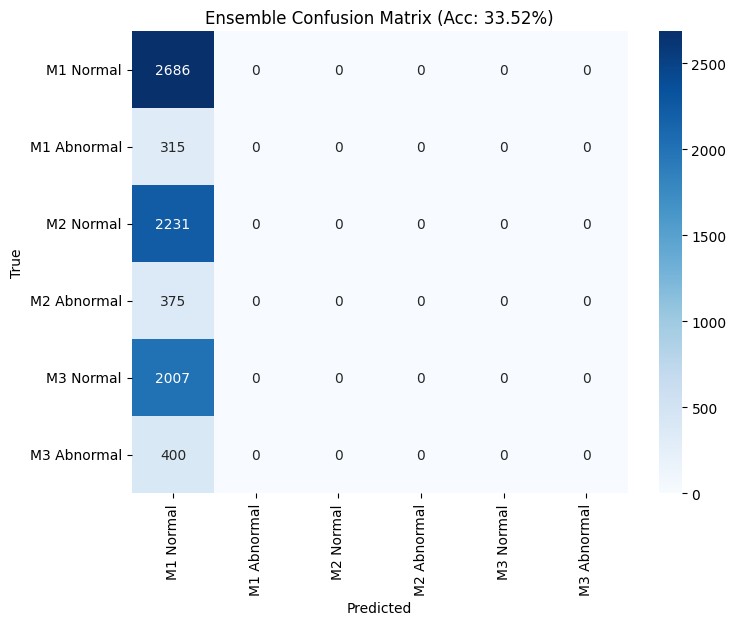

In [10]:
print("\n" + "="*50)
print("Ensemble Evaluation on Test Set")
model_A.eval()
model_B.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc='  Test '):
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        
        model_A.use_raw_audio = True
        out_A = model_A(inputs)
        
        model_B.use_raw_audio = True
        out_B = model_B(inputs)
        
        out_ens = (torch.softmax(out_A, dim=1) + torch.softmax(out_B, dim=1)) / 2.0
        
        preds = out_ens.argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = 100.0 * (np.array(all_preds) == np.array(all_labels)).mean()
print(f"\nEnsemble Test Accuracy: {test_acc:.2f}%")

print('Classification Report')
print('-'*60)
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_title(f'Ensemble Confusion Matrix (Acc: {test_acc:.2f}%)')
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
plt.show()
